### **Bussiness Problem**

**Create a model that can help predict a species of a penguin based on physical attributes, then we can use that model to help researchers classify penguins in the field, instead of needing an experienced biologist**

In [270]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [271]:
data = pd.read_csv('penguins_size.csv')
data.head()

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


**penguins_size.csv : Simplified data from original penguin data sets.**

- species : penguin species (Chinstrap, Adelie, or Gentoo)
- culmen_length_mm : culmen length (mm)
- culmen_depth_mm : culmen depth (mm)
- flipper_length_mm : flipper length (mm)
- body_mass_g : body mass (g)
- island : island name (Dream, Torgersen , or Biscoe) in the Palmer Archipelago (Antarctica)
- sex : penguin sex

In [272]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   culmen_length_mm   342 non-null    float64
 3   culmen_depth_mm    342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                334 non-null    str    
dtypes: float64(4), str(3)
memory usage: 24.9 KB


In [273]:
data.isnull().sum()

species               0
island                0
culmen_length_mm      2
culmen_depth_mm       2
flipper_length_mm     2
body_mass_g           2
sex                  10
dtype: int64

### **EDA**

In [274]:
data.species.unique()

<ArrowStringArray>
['Adelie', 'Chinstrap', 'Gentoo']
Length: 3, dtype: str

In [275]:
data.species.value_counts()

species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

In [276]:
data.island.unique()

<ArrowStringArray>
['Torgersen', 'Biscoe', 'Dream']
Length: 3, dtype: str

In [277]:
data.island.value_counts()

island
Biscoe       168
Dream        124
Torgersen     52
Name: count, dtype: int64

In [278]:
data.culmen_depth_mm.isnull().sum()

np.int64(2)

In [279]:
data.sex.unique()

<ArrowStringArray>
['MALE', 'FEMALE', nan, '.']
Length: 4, dtype: str

In [280]:
data =data[data.sex!='.']
data.shape

(343, 7)

<Axes: ylabel='culmen_length_mm'>

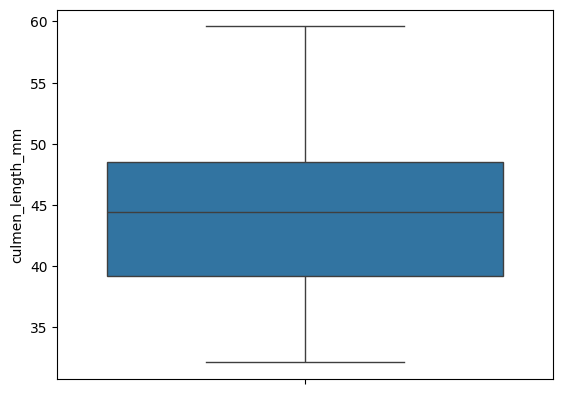

In [281]:
sns.boxplot(data.culmen_length_mm)

<Axes: ylabel='culmen_depth_mm'>

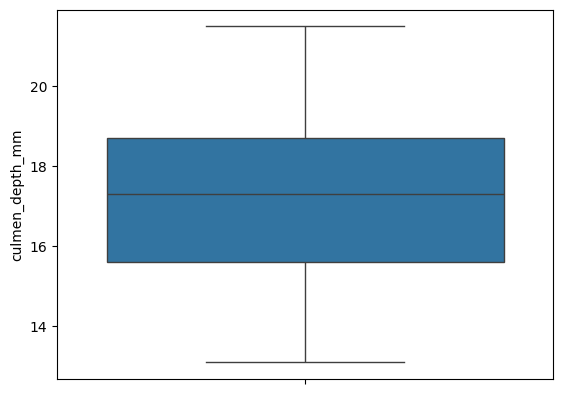

In [282]:
sns.boxplot(data.culmen_depth_mm)

<Axes: ylabel='flipper_length_mm'>

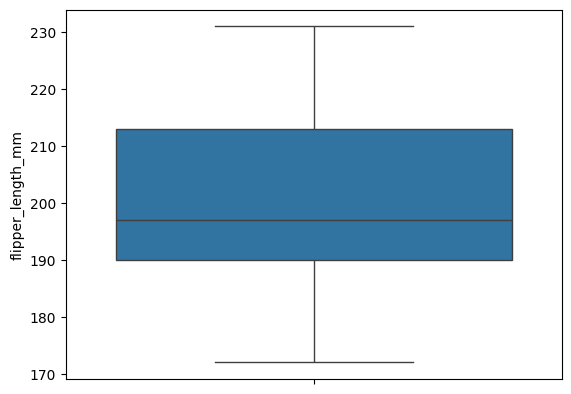

In [283]:
sns.boxplot(data.flipper_length_mm)

<Axes: ylabel='body_mass_g'>

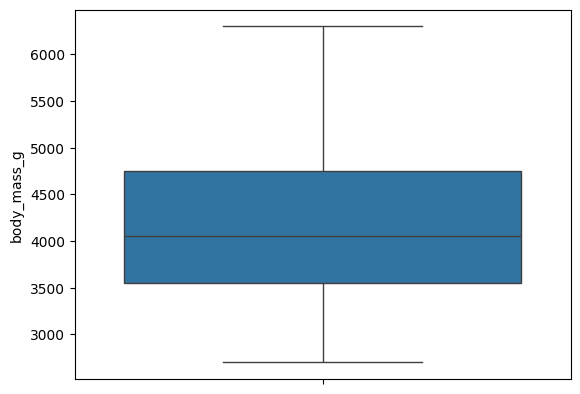

In [284]:
sns.boxplot(data.body_mass_g)

<Axes: xlabel='sex', ylabel='count'>

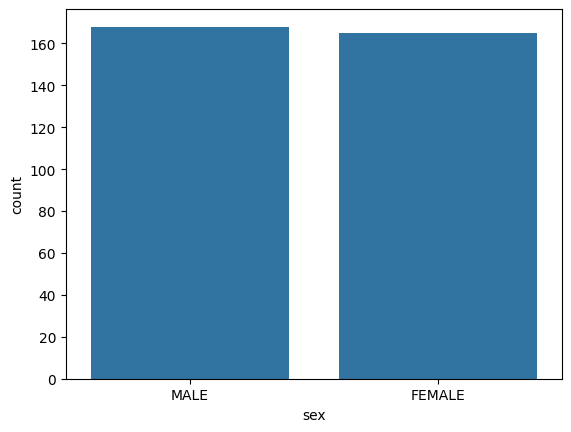

In [285]:
sns.countplot(x = 'sex', data= data)

<Axes: xlabel='species', ylabel='count'>

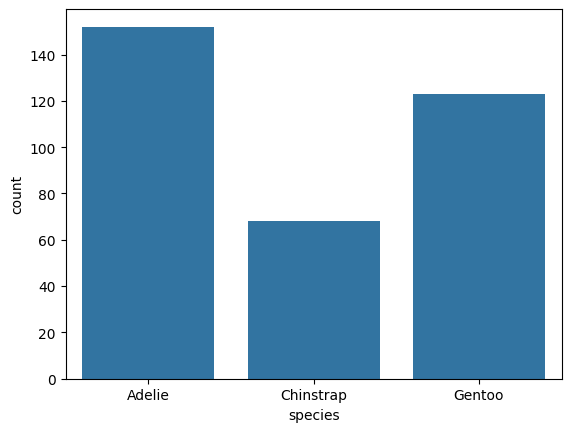

In [286]:
sns.countplot(x ='species', data=data)

<Axes: xlabel='island', ylabel='count'>

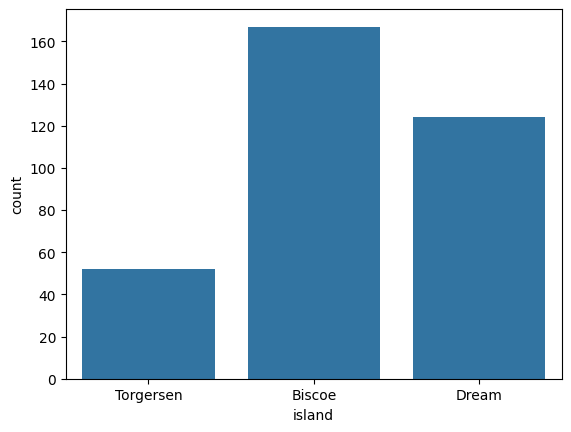

In [287]:
sns.countplot(x = 'island', data=data)

In [288]:
pd.crosstab(data.species, data.island, margins= True)

island,Biscoe,Dream,Torgersen,All
species,,,,
Adelie,44,56,52,152
Chinstrap,0,68,0,68
Gentoo,123,0,0,123
All,167,124,52,343


In [289]:
pd.crosstab(data.species, data.sex, margins=True)

sex,FEMALE,MALE,All
species,,,
Adelie,73,73,146
Chinstrap,34,34,68
Gentoo,58,61,119
All,165,168,333


In [290]:
data.describe()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
count,341.000000,341.000000,341.000000,341.000000
mean,43.920235,17.155425,200.868035,4199.780059
std,5.467516,1.976124,14.055255,802.300201
min,32.100000,13.100000,172.000000,2700.000000
25%,39.200000,15.600000,190.000000,3550.000000
50%,44.400000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.000000,4750.000000
max,59.600000,21.500000,231.000000,6300.000000


<Axes: xlabel='culmen_length_mm', ylabel='culmen_depth_mm'>

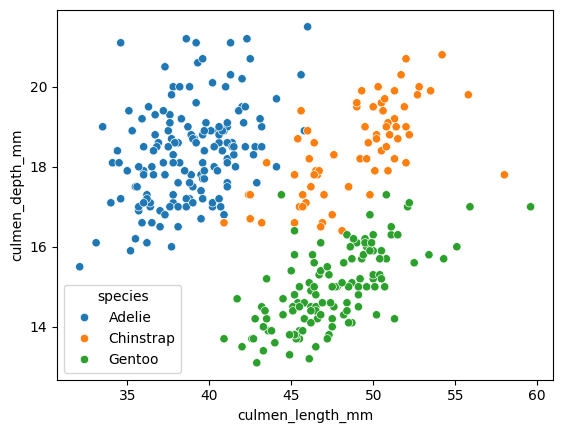

In [291]:
sns.scatterplot(x='culmen_length_mm', y = 'culmen_depth_mm',data=data,hue='species')

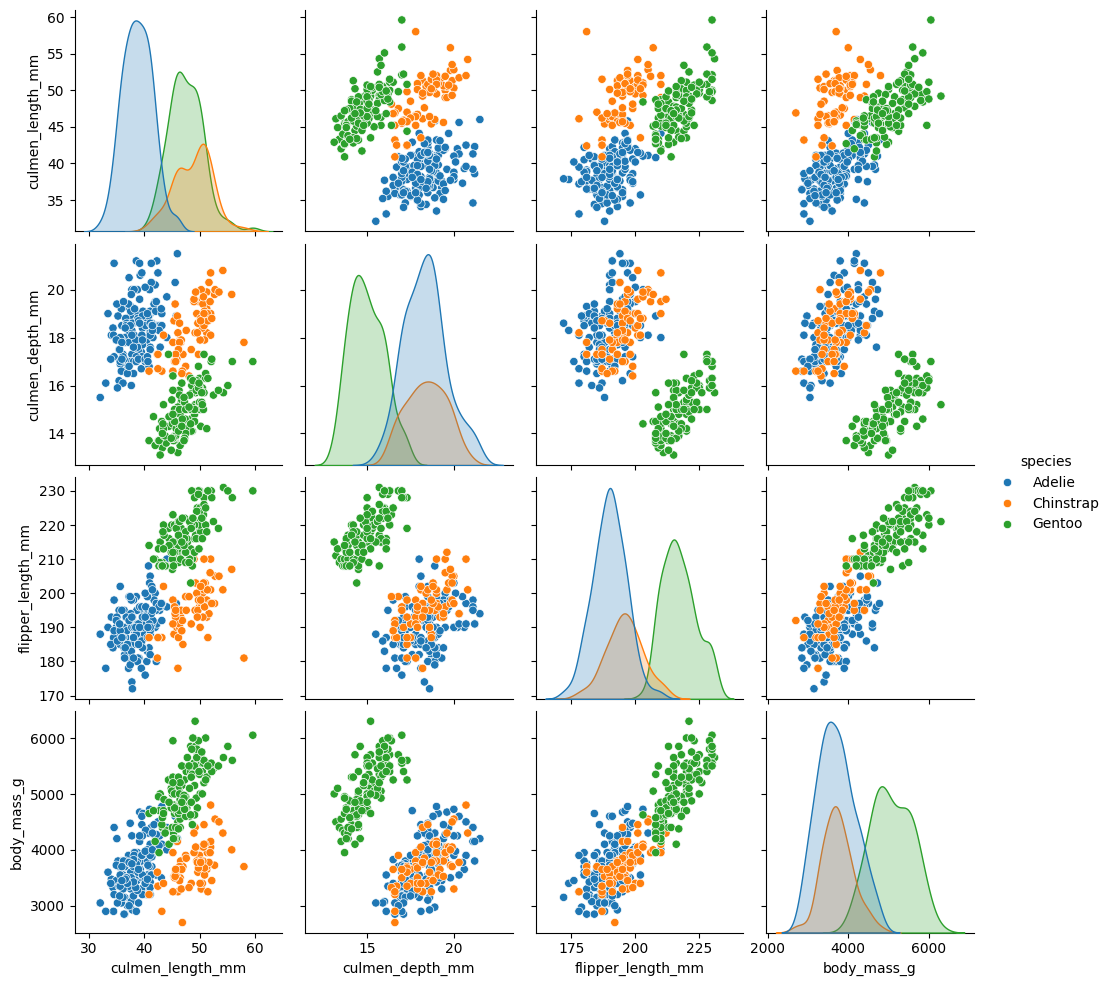

In [292]:
sns.pairplot(data, hue = 'species')

In [293]:
data.species.unique()

<ArrowStringArray>
['Adelie', 'Chinstrap', 'Gentoo']
Length: 3, dtype: str

In [294]:
data.species = data.species.replace({
    'Adelie' :0,
    'Chinstrap':1,
    'Gentoo':2

}).astype('int')

In [295]:
data.species

0      0
1      0
2      0
3      0
4      0
      ..
339    2
340    2
341    2
342    2
343    2
Name: species, Length: 343, dtype: int64

In [296]:
data.island.unique()


<ArrowStringArray>
['Torgersen', 'Biscoe', 'Dream']
Length: 3, dtype: str

In [297]:
data.island = data.island.replace({
    'Torgersen':2,
    'Biscoe':0,
    'Dream':1
}).astype('int')

In [298]:
data.island

0      2
1      2
2      2
3      2
4      2
      ..
339    0
340    0
341    0
342    0
343    0
Name: island, Length: 343, dtype: int64

In [299]:
data.info()

<class 'pandas.DataFrame'>
Index: 343 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            343 non-null    int64  
 1   island             343 non-null    int64  
 2   culmen_length_mm   341 non-null    float64
 3   culmen_depth_mm    341 non-null    float64
 4   flipper_length_mm  341 non-null    float64
 5   body_mass_g        341 non-null    float64
 6   sex                333 non-null    str    
dtypes: float64(4), int64(2), str(1)
memory usage: 23.1 KB


In [300]:
data.sex.unique()

<ArrowStringArray>
['MALE', 'FEMALE', nan]
Length: 3, dtype: str

In [301]:
data.sex = data.sex.fillna(data.sex.mode()[0])

In [302]:
data.sex.unique()

<ArrowStringArray>
['MALE', 'FEMALE']
Length: 2, dtype: str

In [303]:
data.sex = data.sex.replace({
    'FEMALE':0,
    'MALE':1
}).astype('int')

In [304]:
data.corr()

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
species,1.000000,-0.634561,0.732588,-0.743654,0.853717,0.749896,0.006870
island,-0.634561,1.000000,-0.353802,0.570213,-0.564532,-0.560529,0.005465
culmen_length_mm,0.732588,-0.353802,1.000000,-0.235015,0.657102,0.595476,0.323358
culmen_depth_mm,-0.743654,0.570213,-0.235015,1.000000,-0.582964,-0.470963,0.358191
flipper_length_mm,0.853717,-0.564532,0.657102,-0.582964,1.000000,0.870956,0.241768
body_mass_g,0.749896,-0.560529,0.595476,-0.470963,0.870956,1.000000,0.407915
sex,0.006870,0.005465,0.323358,0.358191,0.241768,0.407915,1.000000


In [305]:
data.culmen_length_mm.mean()

np.float64(43.920234604105566)

In [306]:
data.culmen_depth_mm.mean()

np.float64(17.15542521994135)

In [307]:
data.flipper_length_mm.mean()

np.float64(200.86803519061584)

In [308]:
data.body_mass_g.mean()

np.float64(4199.780058651027)

In [309]:
data.culmen_depth_mm=data.culmen_depth_mm.fillna(data.culmen_depth_mm.mean())
data.culmen_length_mm=data.culmen_length_mm.fillna(data.culmen_length_mm.mean())
data.flipper_length_mm=data.flipper_length_mm.fillna(data.flipper_length_mm.mean())
data.body_mass_g=data.body_mass_g.fillna(data.body_mass_g.mean())

In [310]:
data.isnull().sum()

species              0
island               0
culmen_length_mm     0
culmen_depth_mm      0
flipper_length_mm    0
body_mass_g          0
sex                  0
dtype: int64

### **encoding**

In [311]:
pd.get_dummies(data.drop('species', axis = 1), drop_first=True)

,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,2,39.100000,18.700000,181.000000,3750.000000,1
1,2,39.500000,17.400000,186.000000,3800.000000,0
2,2,40.300000,18.000000,195.000000,3250.000000,0
3,2,43.920235,17.155425,200.868035,4199.780059,1
4,2,36.700000,19.300000,193.000000,3450.000000,0
...,...,...,...,...,...,...
339,0,43.920235,17.155425,200.868035,4199.780059,1
340,0,46.800000,14.300000,215.000000,4850.000000,0
341,0,50.400000,15.700000,222.000000,5750.000000,1
342,0,45.200000,14.800000,212.000000,5200.000000,0


In [312]:
X = data.drop('species', axis = 1)
y = data['species']

### **train test split**

In [313]:

Train = []
Test = []
CV =[]

for i in range(1,101):
    from sklearn.model_selection import train_test_split
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=i)

    from sklearn.tree import DecisionTreeClassifier
    dec_default  = DecisionTreeClassifier()
    dec_default.fit(X_train, y_train)
    # dec_default.f(X_train, y_train)

    y_pred_train = dec_default.predict(X_train)
    y_Pred_test = dec_default.predict(X_test)

    from sklearn.metrics import accuracy_score
    Train.append(accuracy_score(y_train, y_pred_train))
    Test.append(accuracy_score(y_test,y_Pred_test))

    from sklearn.model_selection import cross_val_score
    CV.append(cross_val_score(dec_default, X_train, y_train, cv = 5, scoring='accuracy').mean())

em = pd.DataFrame({'Train':Train,'Test':Test,'CV':CV})

gm = em[(abs(em['Train']-em['Test'])<=0.05)& (abs(em['Test']-em['CV'])<=0.05)]

rs = gm[gm['CV']==gm['CV'].max()].index.to_list()[0]
print('Best random_state number : ',rs)



Best random_state number :  4


In [320]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=101)

In [322]:
from sklearn.tree import DecisionTreeClassifier

dtc = DecisionTreeClassifier(random_state=101)
dtc.fit(X_train, y_train)

y_train_pred = dtc.predict(X_train)
y_test_pred = dtc.predict(X_test)

from sklearn.metrics  import accuracy_score
print(accuracy_score(y_train, y_train_pred))

print(accuracy_score(y_test, y_test_pred))

from sklearn.model_selection import cross_val_score

score = cross_val_score(dtc, X, y , cv = 5)

print(score)
score.mean()


1.0
0.9855072463768116
[1.         0.98550725 0.97101449 0.97058824 0.98529412]


np.float64(0.9824808184143222)

## **Modelling**

In [323]:
from sklearn.tree import DecisionTreeClassifier

In [326]:
dtc = DecisionTreeClassifier(random_state=101)
dtc.fit(X_train, y_train)


train_prediction= dtc.predict(X_train)
test_prediction= dtc.predict(X_test)

# accuracy

from sklearn.metrics import accuracy_score
print(accuracy_score(y_train,train_prediction))
print(accuracy_score(y_test,test_prediction))

# cross validation score

from sklearn.model_selection import cross_val_score
score=cross_val_score(dtc,X,y,cv=5)
print(score)

score.mean()

1.0
0.9855072463768116
[1.         0.98550725 0.97101449 0.97058824 0.98529412]


np.float64(0.9824808184143222)

In [328]:
from sklearn.metrics import confusion_matrix
confusion_matrix(y_test,test_prediction)

array([[30,  1,  0],
       [ 0, 16,  0],
       [ 0,  0, 22]])

In [330]:
from sklearn.metrics import classification_report

print(classification_report(y_test,test_prediction))

              precision    recall  f1-score   support

           0       1.00      0.97      0.98        31
           1       0.94      1.00      0.97        16
           2       1.00      1.00      1.00        22

    accuracy                           0.99        69
   macro avg       0.98      0.99      0.98        69
weighted avg       0.99      0.99      0.99        69



In [331]:
dtc.feature_importances_

array([0.08279322, 0.32998048, 0.00566091, 0.53243166, 0.01573461,
       0.03339912])

In [332]:
pd.DataFrame(index=X.columns,data=dtc.feature_importances_,columns=['feature importance'])

,feature importance
island,0.082793
culmen_length_mm,0.329980
culmen_depth_mm,0.005661
flipper_length_mm,0.532432
body_mass_g,0.015735
sex,0.033399


## **Visualized the tree**

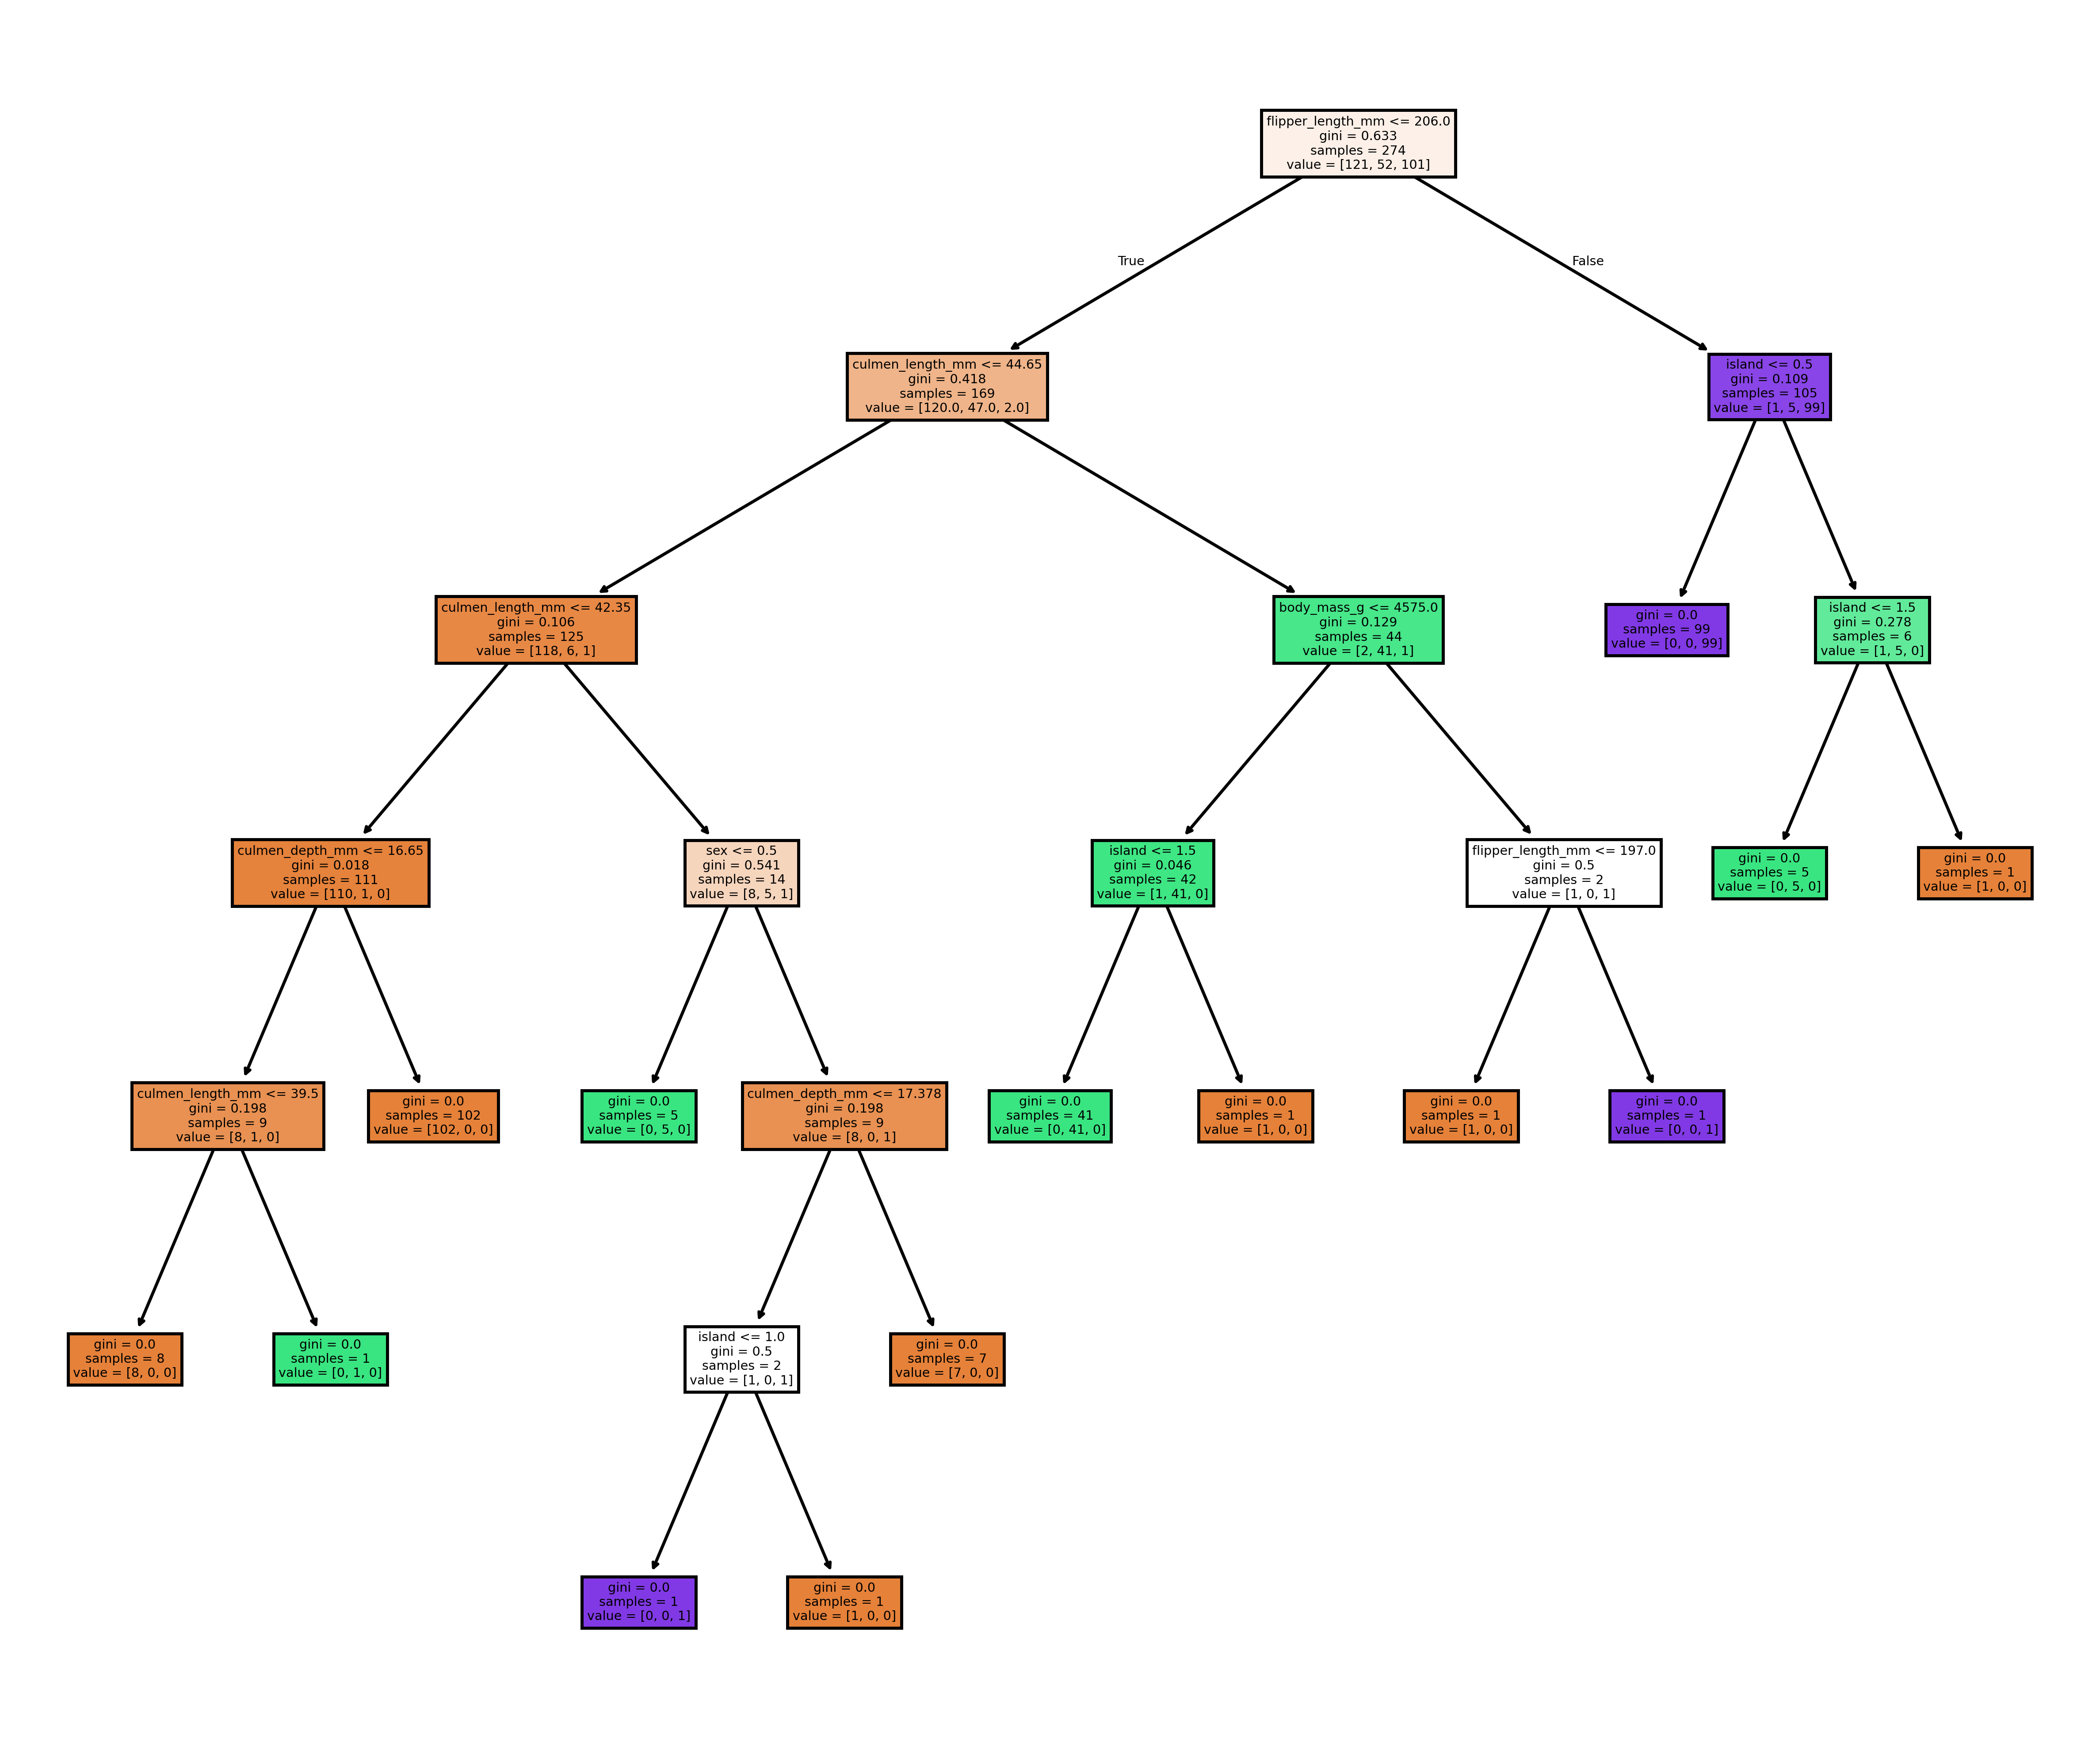

In [333]:
from sklearn.tree import plot_tree

plt.figure(figsize=(12,10),dpi=500)
plot_tree(dtc,filled=True,feature_names= X.columns)
plt.show()